# 1. Data Loading and Exploration

In [28]:
#import pandas as pd

# Load the dataset
#df = pd.read_csv('/content/fraud_oracle.csv')

# Display the first 5 rows
#display(df.head())

In [29]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:

import pandas as pd

file_path = (
    "/content/drive/MyDrive/"
    "Insurance Project Dataset/fraud_oracle.csv")


df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (15420, 33)


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,...,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,...,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


In [31]:
print(df.shape)

(15420, 33)


In [32]:
# Check Column names with data types
df.info()

# Check Missing values
print("\nMissing values: ")
print(df.isnull().sum().sort_values(ascending=False))

# Check the target variable
print("\nFraud counts: ")
print(df["FraudFound_P"].value_counts())

print("\nFraud percentages: ")
print((df["FraudFound_P"].value_counts(normalize=True) * 100).round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-null  object
 4   AccidentArea          15420 non-null  object
 5   DayOfWeekClaimed      15420 non-null  object
 6   MonthClaimed          15420 non-null  object
 7   WeekOfMonthClaimed    15420 non-null  int64 
 8   Sex                   15420 non-null  object
 9   MaritalStatus         15420 non-null  object
 10  Age                   15420 non-null  int64 
 11  Fault                 15420 non-null  object
 12  PolicyType            15420 non-null  object
 13  VehicleCategory       15420 non-null  object
 14  VehiclePrice          15420 non-null  object
 15  FraudFound_P          15420 non-null

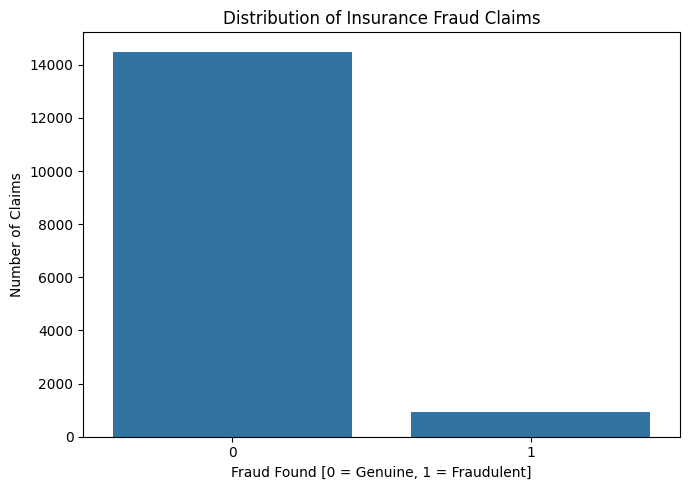

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="FraudFound_P")

plt.title("Distribution of Insurance Fraud Claims")
plt.xlabel("Fraud Found [0 = Genuine, 1 = Fraudulent]")
plt.ylabel("Number of Claims")

plt.tight_layout()
plt.show()

# 2. Data Preprocessing

In [34]:
import numpy as np
from sklearn.model_selection import train_test_split

# To work on a copy of the original dataset
data = df.copy()

# Make invalid claim-day value as missing
data["DayOfWeekClaimed"] = data["DayOfWeekClaimed"].replace("0", np.nan)

# Convert identifiers, codes into categorical variables
data["RepNumber"] = data["RepNumber"].astype(str)
data["Year"] = data["Year"].astype(str)

# Drop target value from input features
X = data.drop(columns=["FraudFound_P", "PolicyNumber"])
y = data["FraudFound_P"]

# Train-test Split, 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print("Training features: ", X_train.shape)
print("Testing features: ", X_test.shape)

print("\nTraining fraud rate: ")
print(round(y_train.mean() * 100, 2), "%")

print("\nTesting fraud rate: ")
print(round(y_test.mean() * 100, 2), "%")

Training features:  (12336, 31)
Testing features:  (3084, 31)

Training fraud rate: 
5.98 %

Testing fraud rate: 
6.0 %


In [35]:

import pandas as pd

# Dataset summary
total_records = len(df)
genuine_claims = (df["FraudFound_P"] == 0).sum()
fraudulent_claims = (df["FraudFound_P"] == 1).sum()

genuine_percentage = genuine_claims / total_records * 100
fraud_percentage = fraudulent_claims / total_records * 100

# Safely get length of train/test sets if they exist
training_count = f"{len(X_train):,}" if 'X_train' in globals() else "Not split yet"
testing_count = f"{len(X_test):,}" if 'X_test' in globals() else "Not split yet"

# Create the summary table
dataset_summary = pd.DataFrame({
    "Item": [ "Total records",
        "Genuine claims",
        "Fraudulent claims",
        "Genuine claims (%)",
        "Fraudulent claims (%)",
        "Training records",
        "Test records"
    ],
    "Value": [
        f"{total_records:,}",
        f"{genuine_claims:,}",
        f"{fraudulent_claims:,}",
        f"{genuine_percentage:.2f}%",
        f"{fraud_percentage:.2f}%",
        training_count,
        testing_count
    ]
})

print("Table 1 - Dataset Summary")
display(dataset_summary)

Table 1 - Dataset Summary


,Item,Value
0,Total records,"15,420"
1,Genuine claims,"14,497"
2,Fraudulent claims,923
3,Genuine claims (%),94.01%
4,Fraudulent claims (%),5.99%
5,Training records,"12,336"
6,Test records,"3,084"


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Check column types using training data
categorical_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

numerical_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

print("Categorical features:", len(categorical_cols))
print("Numerical features:", len(numerical_cols))

# Process numerical features
numeric_pipeline = Pipeline([("Simple_Inputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

# Process categorical features
categorical_pipeline = Pipeline([("Simple_Inputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("[Successfully Created Preprocessing pipeline]")

Categorical features: 26
Numerical features: 5
[Successfully Created Preprocessing pipeline]


# 3. Baseline Model Development and Evaluation



In [37]:
#Training ML Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),

    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=None, random_state=42, n_jobs=-1),

    "XGBoost": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", random_state=42, n_jobs=-1)
}

trained_models = {}

for name, model in models.items():
    print(f"Training {name} Model")

    pipeline = Pipeline([("preprocessor", preprocessor), ("model", model)])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(f"{name} completed!!")

print("\nAll models trained successfully!!")

Training Logistic Regression Model
Logistic Regression completed!!
Training Random Forest Model
Random Forest completed!!
Training XGBoost Model
XGBoost completed!!

All models trained successfully!!


In [38]:
#Evaluation of Three ML Models

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report)

results = []
predictions = {}

for name, pipeline in trained_models.items():

    # Prediction classes and fraud probabilities
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    predictions[name] = { "y_pred": y_pred, "y_prob": y_prob}

    results.append({"Model": name, "Accuracy": accuracy_score(y_test, y_pred), "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.9400,0.50,0.0108,0.0212,0.8109
Random Forest,0.9407,0.75,0.0162,0.0317,0.8317
XGBoost,0.9413,1.00,0.0216,0.0423,0.8485


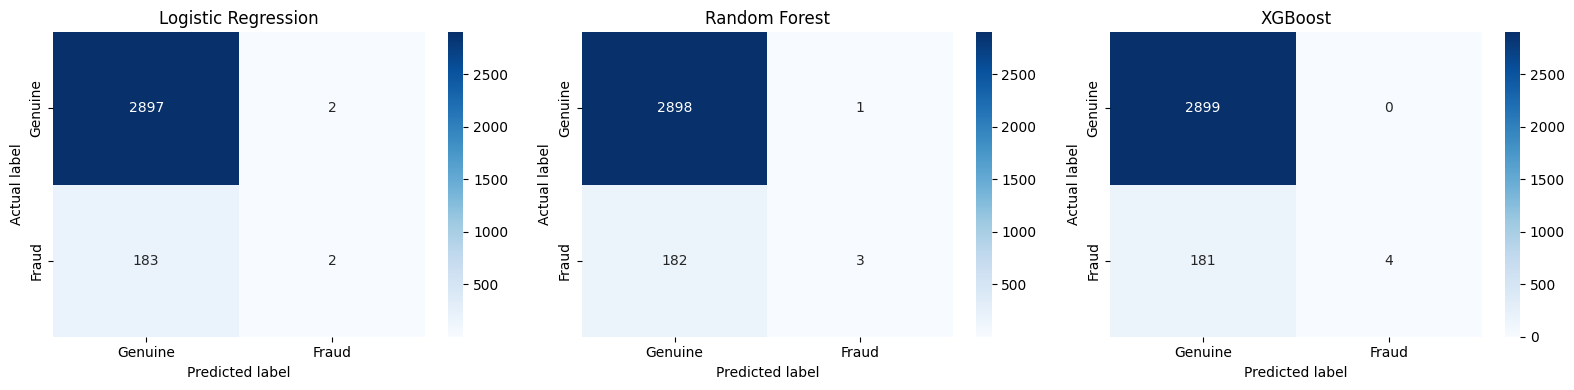

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, prediction) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, prediction["y_pred"], labels=[0, 1])

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Genuine", "Fraud"], yticklabels=["Genuine", "Fraud"], ax=ax)

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()

In [40]:
results_df.to_csv("baseline_model_results.csv")
print("Baseline results successfully saved!!")

Baseline results successfully saved!!


In [41]:
from google.colab import files

files.download("baseline_model_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 4. Class-Imbalance Handling and Comparison

In [42]:
from sklearn.base import clone

# Calculation of the ratio of genuine to fraudulent claims
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

fraud_ratio = negative_count / positive_count

print("Genuine claims in training set:", negative_count)
print("Fraudulent claims in training set:", positive_count)
print("XGBoost scale_pos_weight:", round(fraud_ratio, 2))

weighted_models = { "Logistic Regression (balanced)": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),

"Random Forest (balanced)": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=42, n_jobs=-1),

"XGBoost (weighted)": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=fraud_ratio, eval_metric="logloss", random_state=42, n_jobs=-1)
}

weighted_trained_models = {}

for name, model in weighted_models.items():
    pipeline = Pipeline([("preprocessor", clone(preprocessor)), ("model", model)])

    pipeline.fit(X_train, y_train)
    weighted_trained_models[name] = pipeline

    print(f"{name} trained successfully.")

Genuine claims in training set: 11598
Fraudulent claims in training set: 738
XGBoost scale_pos_weight: 15.72
Logistic Regression (balanced) trained successfully.
Random Forest (balanced) trained successfully.
XGBoost (weighted) trained successfully.


In [43]:
weighted_results = []
weighted_predictions = {}

for name, pipeline in weighted_trained_models.items():
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    weighted_predictions[name] = { "y_pred": y_pred, "y_prob": y_prob}

    weighted_results.append({ "Model": name, "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob) })

weighted_results_df = pd.DataFrame(weighted_results).set_index("Model")

display(weighted_results_df.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression (balanced),0.6543,0.1326,0.8595,0.2298,0.8037
Random Forest (balanced),0.9403,1.0000,0.0054,0.0108,0.8327
XGBoost (weighted),0.7108,0.1558,0.8649,0.2640,0.8523


In [44]:
#class imblance comparison

baseline_comparison = results_df.copy()
baseline_comparison["Experiment"] = "Baseline"

weighted_comparison = weighted_results_df.copy()
weighted_comparison["Experiment"] = "Class weighted"

comparison_df = pd.concat([ baseline_comparison, weighted_comparison ])

display(comparison_df[["Experiment", "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].round(4))

,Experiment,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,,
Logistic Regression,Baseline,0.9400,0.5000,0.0108,0.0212,0.8109
Random Forest,Baseline,0.9407,0.7500,0.0162,0.0317,0.8317
XGBoost,Baseline,0.9413,1.0000,0.0216,0.0423,0.8485
Logistic Regression (balanced),Class weighted,0.6543,0.1326,0.8595,0.2298,0.8037
Random Forest (balanced),Class weighted,0.9403,1.0000,0.0054,0.0108,0.8327
XGBoost (weighted),Class weighted,0.7108,0.1558,0.8649,0.2640,0.8523


# 5. Model Evaluation and Visualisation

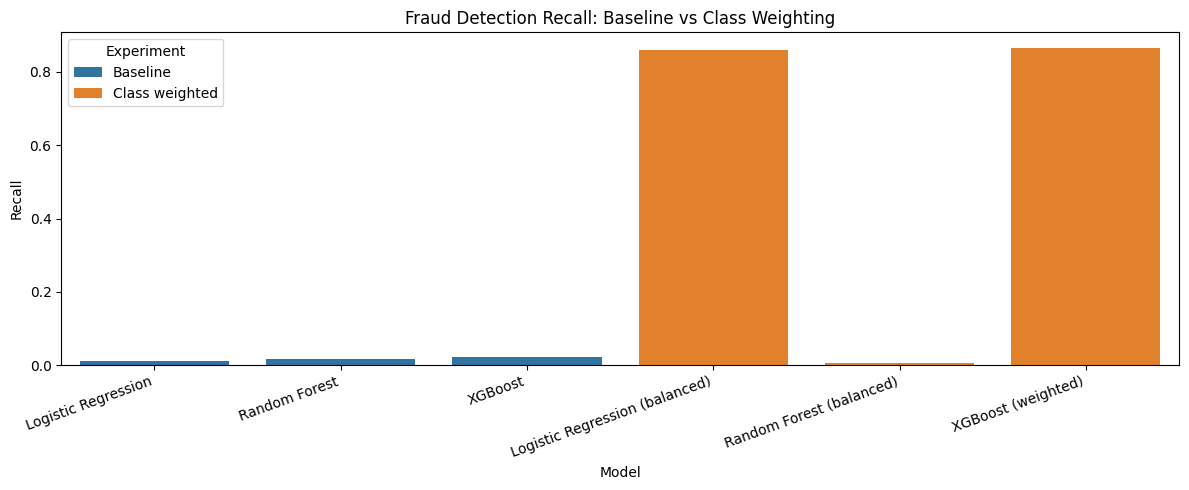

In [45]:
plot_data = comparison_df.reset_index()

plt.figure(figsize=(12, 5))

sns.barplot(data=plot_data, x="Model", y="Recall", hue="Experiment")

plt.title("Fraud Detection Recall: Baseline vs Class Weighting")
plt.ylabel("Recall")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

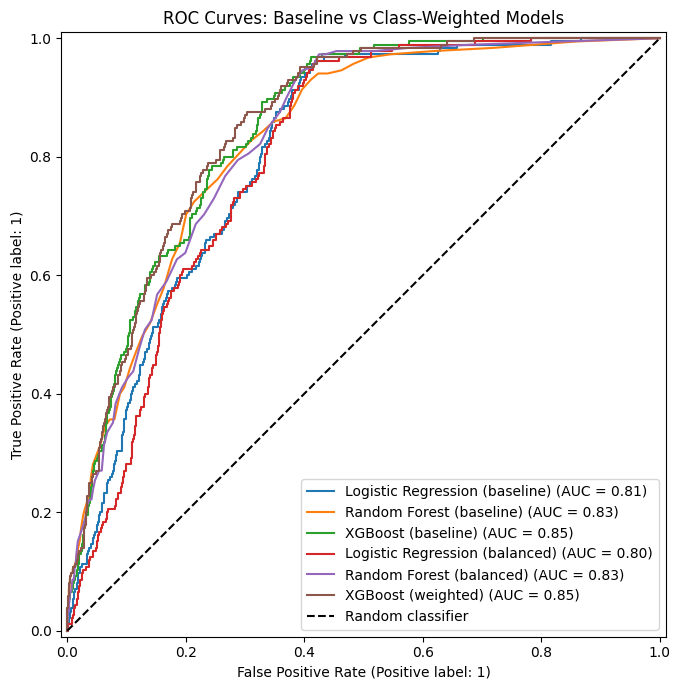

In [46]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(9, 7))

for name, prediction in predictions.items():
    RocCurveDisplay.from_predictions(y_test, prediction["y_prob"], name=f"{name} (baseline)", ax=ax)

for name, prediction in weighted_predictions.items():
    RocCurveDisplay.from_predictions(y_test, prediction["y_prob"], name=name, ax=ax)

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("ROC Curves: Baseline vs Class-Weighted Models")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

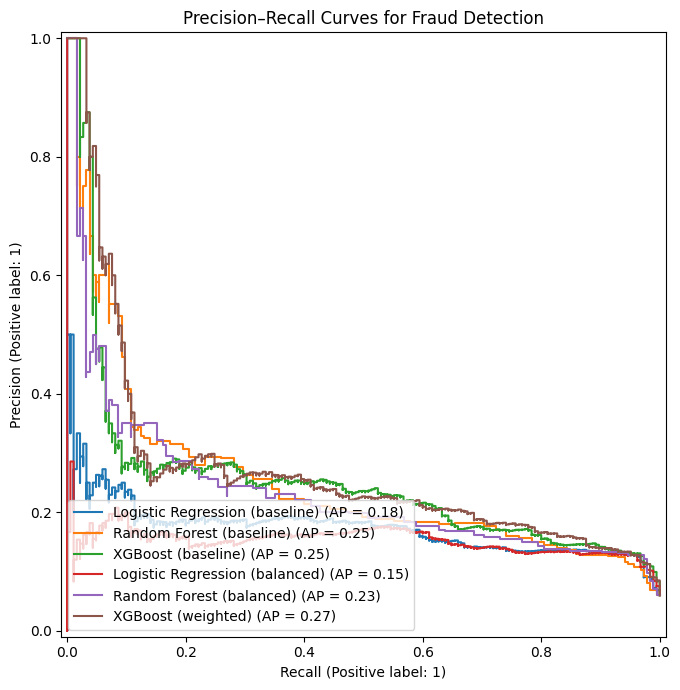

In [47]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))
ax = plt.gca()

# Baseline models
for name, prediction in predictions.items():
    PrecisionRecallDisplay.from_predictions(y_test, prediction["y_prob"], name=f"{name} (baseline)", ax=ax)

# Class-weighted models
for name, prediction in weighted_predictions.items():
    PrecisionRecallDisplay.from_predictions(y_test, prediction["y_prob"], name=name, ax=ax)

plt.title("Precision–Recall Curves for Fraud Detection")
plt.tight_layout()
plt.show()

# 6. SHAP Explainability

The best model is : XGBoost (weighted)



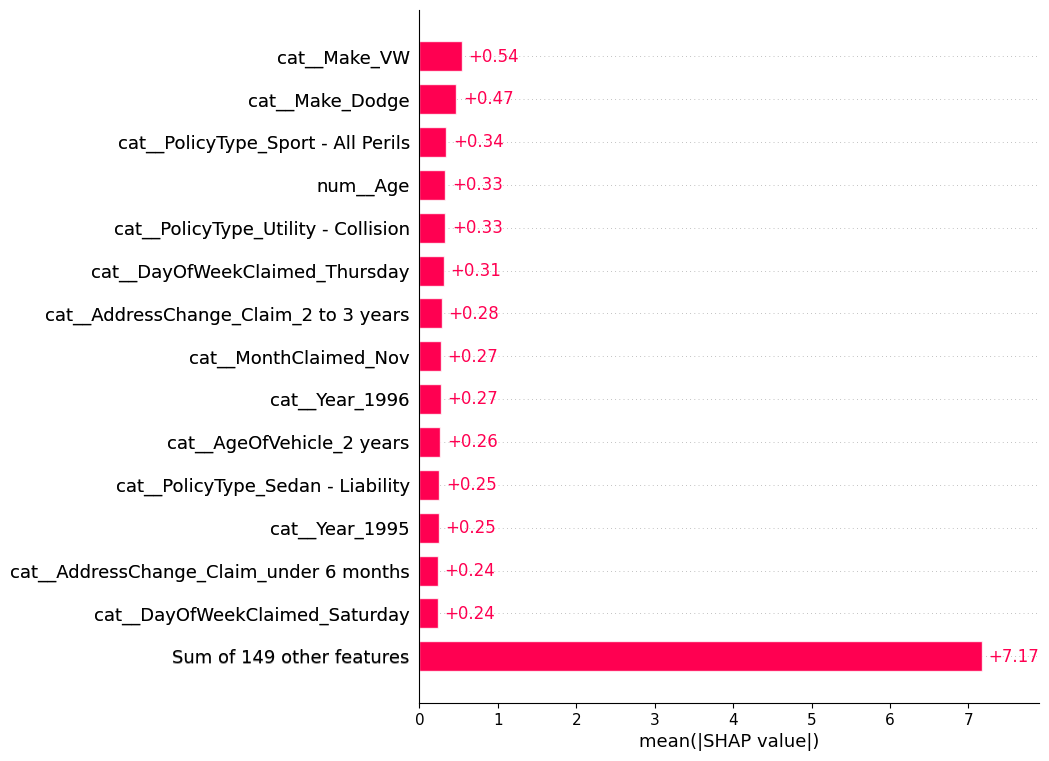

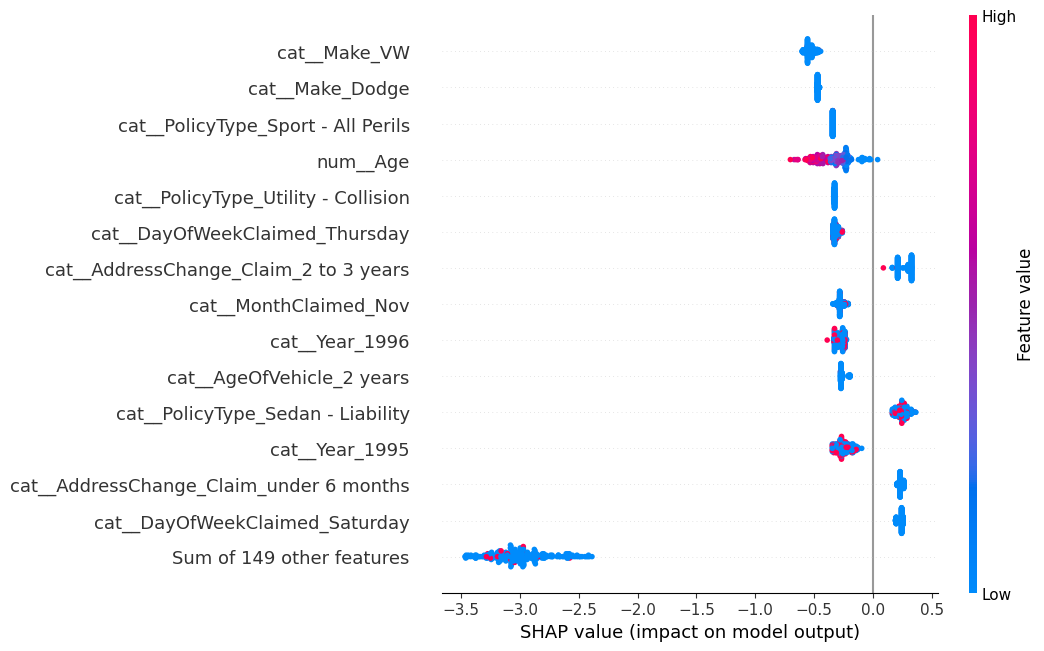

In [48]:
import shap
import scipy.sparse as sp

# Select the weighted XGBoost model
best_model_name = "XGBoost (weighted)"
best_pipeline = weighted_trained_models[best_model_name]

fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
fitted_model = best_pipeline.named_steps["model"]

# Transform the test features
X_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

# Use a manageable sample
X_sample = X_transformed[:300]

if sp.issparse(X_sample):
    X_sample = X_sample.toarray()

X_sample_df = pd.DataFrame(X_sample, columns=feature_names)

print('The best model is : ' + best_model_name +'\n')

# Explain the weighted XGBoost model
explainer = shap.TreeExplainer(fitted_model)
shap_values = explainer(X_sample_df)

# Global feature importance
shap.plots.bar(shap_values, max_display=15)

# Effect of features on individual predictions
shap.plots.beeswarm(shap_values, max_display=15)

Examples available in the SHAP sample:
Correctly detected fraud: 19
False positives: 88
Missed fraud: 4

Table 4. Individual cases for SHAP analysis


,Case,Test sample position,Actual label,Model prediction,Fraud probability,Evidence to discuss
0,1,7,Fraud,Fraud,0.6624,Positive contributions: cat__AddressChange_Cla...
1,2,3,Genuine,Fraud,0.6561,Positive contributions: cat__AddressChange_Cla...
2,3,16,Fraud,Genuine,0.2942,Positive contributions: cat__AddressChange_Cla...



Case: Correctly detected fraud
Test sample position: 7
Actual label: Fraud
Prediction: Fraud
Predicted fraud probability: 0.6624


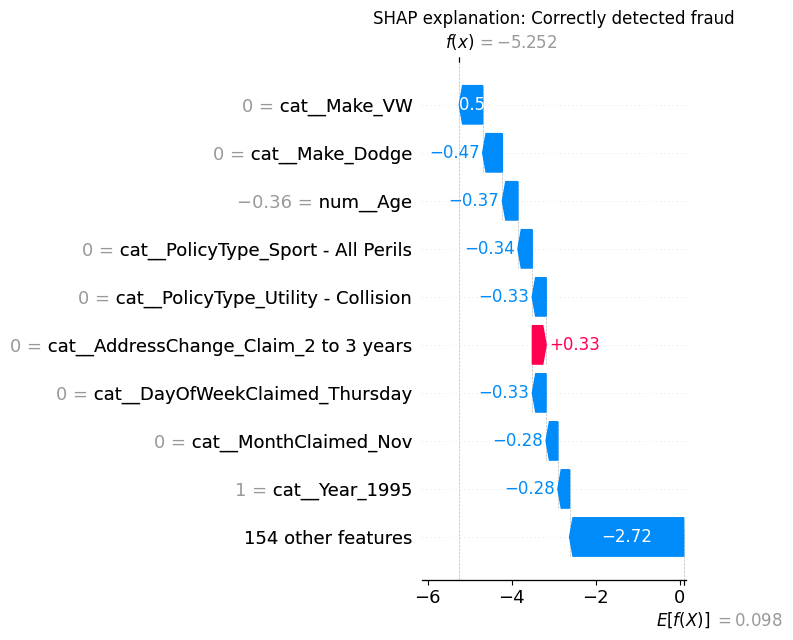


Case: False positive
Test sample position: 3
Actual label: Genuine
Prediction: Fraud
Predicted fraud probability: 0.6561


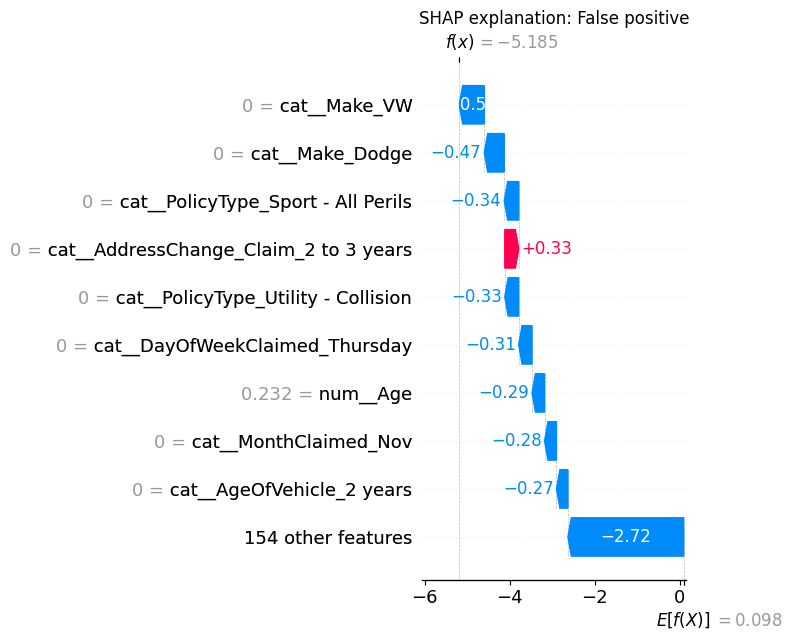


Case: Missed fraud
Test sample position: 16
Actual label: Fraud
Prediction: Genuine
Predicted fraud probability: 0.2942


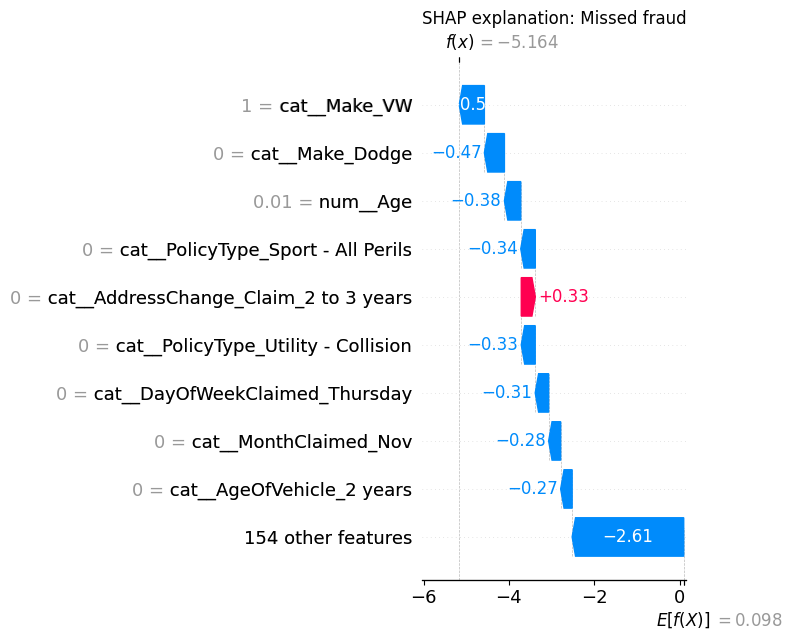

In [49]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# 1. Get real predictions from weighted XGBoost
y_true = np.asarray(y_test).ravel()
y_pred = best_pipeline.predict(X_test)
y_prob = best_pipeline.predict_proba(X_test)[:, 1]

# SHAP values to explain the first rows of X_test only
n = len(X_sample_df)

assert n == len(shap_values), ("The number of SHAP rows does not match X_sample_df.")

# Find available examples within the SHAP sample
correct_fraud = np.where((y_true[:n] == 1) & (y_pred[:n] == 1))[0]

false_positive = np.where((y_true[:n] == 0) & (y_pred[:n] == 1))[0]

missed_fraud = np.where((y_true[:n] == 1) & (y_pred[:n] == 0))[0]

print("Examples available in the SHAP sample:")
print("Correctly detected fraud:", len(correct_fraud))
print("False positives:", len(false_positive))
print("Missed fraud:", len(missed_fraud))

# 2. Build Table 4 using real cases
case_types = [
    ("Correctly detected fraud", correct_fraud),
    ("False positive", false_positive),
    ("Missed fraud", missed_fraud)
]

table_rows = []
selected_cases = []

for description, indices in case_types:
    if len(indices) == 0:
        print(f"No example found for: {description}")
        continue

    # Select the first available example of this type
    i = int(indices[0])
    selected_cases.append((description, i))

    # Get the largest positive and negative SHAP contributions
    values = np.asarray(shap_values[i].values).ravel()
    names = np.asarray(feature_names)

    order_positive = np.argsort(values)[::-1]
    order_negative = np.argsort(values)

    top_positive = [
        f"{names[j]} ({values[j]:+.3f})"
        for j in order_positive[:3]
        if values[j] > 0
    ]

    top_negative = [
        f"{names[j]} ({values[j]:+.3f})"
        for j in order_negative[:3]
        if values[j] < 0
    ]

    evidence = (
        "Positive contributions: "
        + (", ".join(top_positive) or "None among top features")
        + ". Negative contributions: "
        + (", ".join(top_negative) or "None among top features")
        + f". Predicted fraud probability: {y_prob[i]:.4f}."
    )

    actual_label = "Fraud" if y_true[i] == 1 else "Genuine"
    predicted_label = "Fraud" if y_pred[i] == 1 else "Genuine"

    table_rows.append({
        "Case": f"{len(table_rows) + 1}",
        "Test sample position": i,
        "Actual label": actual_label,
        "Model prediction": predicted_label,
        "Fraud probability": round(float(y_prob[i]), 4),
        "Evidence to discuss": evidence
    })

table4 = pd.DataFrame(table_rows)

print("\nTable 4. Individual cases for SHAP analysis")
display(table4)


# 3. Display a waterfall plot for each available case
for description, i in selected_cases:
    print(f"\nCase: {description}")
    print("Test sample position:", i)
    print("Actual label:", "Fraud" if y_true[i] == 1 else "Genuine")
    print("Prediction:", "Fraud" if y_pred[i] == 1 else "Genuine")
    print(f"Predicted fraud probability: {y_prob[i]:.4f}")

    shap.plots.waterfall(shap_values[i], max_display=10, show=False)
    plt.title(f"SHAP explanation: {description}")
    plt.tight_layout()
    plt.show()


In [50]:
if best_model_name == "Logistic Regression":
    X_background = X_test_transformed[:min(100, len(X_test))]

    if sp.issparse(X_background):
        X_background = X_background.toarray()

    background_df = pd.DataFrame(X_background, columns=feature_names)

    explainer = shap.LinearExplainer(fitted_model, background_df)
else:
    explainer = shap.TreeExplainer(fitted_model)

shap_values = explainer(X_sample_df)

print("SHAP analysis completed!!")

SHAP analysis completed!!


# 7. Final Results and Model Export

In [51]:
baseline_export = results_df.copy()
baseline_export["Experiment"] = "Baseline"

weighted_export = weighted_results_df.copy()
weighted_export["Experiment"] = "Class weighted"

final_results = pd.concat([baseline_export, weighted_export])

final_results.to_csv("insurance_fraud_model_comparison.csv")

display(final_results.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Experiment
Model,,,,,,
Logistic Regression,0.9400,0.5000,0.0108,0.0212,0.8109,Baseline
Random Forest,0.9407,0.7500,0.0162,0.0317,0.8317,Baseline
XGBoost,0.9413,1.0000,0.0216,0.0423,0.8485,Baseline
Logistic Regression (balanced),0.6543,0.1326,0.8595,0.2298,0.8037,Class weighted
Random Forest (balanced),0.9403,1.0000,0.0054,0.0108,0.8327,Class weighted
XGBoost (weighted),0.7108,0.1558,0.8649,0.2640,0.8523,Class weighted


In [52]:
import joblib

joblib.dump(weighted_trained_models["XGBoost (weighted)"], "best_insurance_fraud_model.joblib")

print("Selected weighted XGBoost model Saved!!")

Selected weighted XGBoost model Saved!!


In [53]:
from google.colab import files

files.download("insurance_fraud_model_comparison.csv")
files.download("best_insurance_fraud_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>